# Credit Risk Scoring — Retail Banking

Predicting loan default from an **anonymized retail-banking dataset** with an interpretable model (logistic regression).

**Stack:** Python · pandas · scikit-learn · imbalanced-learn (SMOTE) · SHAP

**Approach**
1. Understand and clean the raw data (types, validity rules, contradictory duplicates)
2. Engineer financial ratios (debt-to-income, credit-to-income, total repayment)
3. Train a logistic regression inside a leak-free pipeline (scaling → SMOTE → classifier)
4. Evaluate with cross-validation and a held-out test set, and choose a decision threshold
5. Interpret the model with coefficients, odds ratios and SHAP values

## 1. Setup and Data 

**Data dictionary**

| Column | Description | Raw format |
|---|---|---|
| `birth_date`  | Applicant's date of birth (converted to `age` in years) | text, `dd/mm/yyyy` |
| `profession`  | Applicant's profession | category |
| `salary`  | Monthly salary | number |
| `credit_amount`  | Loan amount | text, comma = thousands separator |
| `duration`  | Loan duration in months | integer |
| `monthly_payment`  | Monthly loan repayment | text, comma = decimal mark |
| `outstanding_credit`  | Amount of other credit currently running (empty = none) | text, comma = decimal mark |
| `default`  | **Target**: 1 = defaulted, 0 = healthy | 0 / 1 |

In [15]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    train_test_split,
)
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# ── Configuration ─────────────────────────────────────────────
RANDOM_STATE = 42
TEST_SIZE = 0.2
TOP_N_PROFESSIONS = 10   # rarer professions are grouped into "other"
N_FOLDS = 3              # small dataset → 3 folds instead of 5


In [ ]:
DATA_PATH = "../data/sample/sample.csv"

df = pd.read_csv(DATA_PATH)

df.head()

,birth_date,profession,salary,credit_amount,duration,monthly_payment,outstanding_credit,default
0,30/04/1987,farmer,0.0,"69,472.23",240,"337,74","3705,68",0
1,01/01/2015,farmer,1845.0,"25,656.46",60,"659,36","906,43",0
2,19/05/1970,driver,2195.0,"60,480.98",400,"472,24",NaN,0
3,05/11/1976,employee,2053.0,"69,681.02",240,"332,31",NaN,0
4,08/01/1977,craftsman,2504.0,"9,194.54",180,"78,65","12125,12",0


# **2. Data Understanding**
Business question: *can we flag loan applications likely to default, using only information available at application time?*
The target `default` is 1 for a defaulted file and 0 for a healthy one.

In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 402 entries, 0 to 401
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   birth_date          402 non-null    str    
 1   profession          402 non-null    str    
 2   salary              402 non-null    float64
 3   credit_amount       402 non-null    str    
 4   duration            402 non-null    int64  
 5   monthly_payment     402 non-null    str    
 6   outstanding_credit  252 non-null    str    
 7   default             402 non-null    int64  
dtypes: float64(1), int64(2), str(5)
memory usage: 25.3 KB


In [18]:
df["default"].value_counts()

default
0    270
1    132
Name: count, dtype: int64

In [19]:
def plot_class_balance(data, title, save_as=None):
    """Pie chart of the healthy / default split."""
    counts = data["default"].value_counts().sort_index()
    labels = ["Healthy" if k == 0 else "Default" for k in counts.index]
    counts.plot(kind="pie", labels=labels, autopct="%1.1f%%", startangle=90)
    plt.title(title)
    plt.ylabel("")
    plt.show()

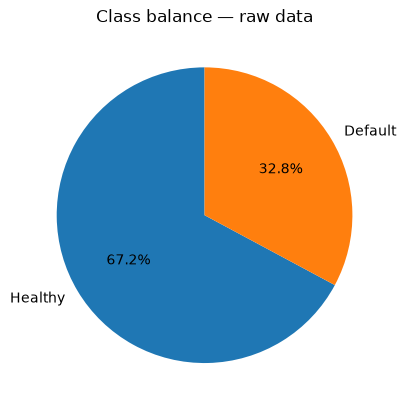

In [20]:
plot_class_balance(df, "Class balance — raw data")

## 3. Data cleaning

### 3.1 Types and formats
- `birth_date` (day-first string) → `age` in years
- Amounts stored as text: decimal comma → decimal point, thousands separator removed
- Missing `outstanding_credit` means no running credit → filled with 0

In [21]:
# Date of birth → age in years (relative to today's date)
df["birth_date"] = pd.to_datetime(df["birth_date"], dayfirst=True)
df["age"] = (pd.Timestamp.today() - df["birth_date"]).dt.days // 365
df = df.drop(columns="birth_date")

In [22]:
df['monthly_payment'] = df['monthly_payment'].astype(str).str.replace(',', '.').str.strip()
df['monthly_payment'] = pd.to_numeric(df['monthly_payment'], errors='coerce')

df['outstanding_credit']=df['outstanding_credit'].astype(str).str.replace(',', '.').str.strip()
df['outstanding_credit'] = pd.to_numeric(df['outstanding_credit'], errors='coerce')
df['outstanding_credit'] = df['outstanding_credit'].fillna(0)

df['credit_amount'] = df['credit_amount'].astype(str).str.replace(',', '').str.strip()
df['credit_amount'] = pd.to_numeric(df['credit_amount'], errors='coerce')

In [23]:
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
profession            0
salary                0
credit_amount         0
duration              0
monthly_payment       0
outstanding_credit    0
default               0
age                   0
dtype: int64


In [24]:
# Rows with a missing value in a modeling variable cannot be used
required = ["age", "salary", "credit_amount", "duration", "monthly_payment", "default"]
n_before = len(df)
df = df.dropna(subset=required)
print(f"Rows dropped for missing values: {n_before - len(df)}")
df.info()

Rows dropped for missing values: 0
<class 'pandas.DataFrame'>
RangeIndex: 402 entries, 0 to 401
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   profession          402 non-null    str    
 1   salary              402 non-null    float64
 2   credit_amount       402 non-null    float64
 3   duration            402 non-null    int64  
 4   monthly_payment     402 non-null    float64
 5   outstanding_credit  402 non-null    float64
 6   default             402 non-null    int64  
 7   age                 402 non-null    int64  
dtypes: float64(4), int64(3), str(1)
memory usage: 25.3 KB


### 3.2 Validity rules
Keep realistic applicants only: age between 18 and 75, strictly positive salary, duration under 350 months.

In [25]:
n_before = len(df)
df = df[df["age"].between(18, 75)]
df = df[df["salary"] > 0]
df = df[df["duration"] < 350]
print(f"Rows removed by validity rules: {n_before - len(df)}")

Rows removed by validity rules: 3


### 3.3 Duplicates and consistency
1. **Contradictory duplicates** — same profile but different labels: the label is unreliable, so all of these rows are removed.
2. **True duplicates** — same profile and same label: keep one.
3. **Impossible loans** — total repayments lower than the borrowed capital would imply a negative interest rate.

In [26]:
n_start = len(df)
dup_keys = ["age", "profession", "salary", "credit_amount", "duration"]

# Step 1 — contradictory duplicates (same profile, different labels)
dups = df[df.duplicated(subset=dup_keys, keep=False)]
contradictory_mask = dups.groupby(dup_keys)["default"].transform("nunique") > 1
contradictory_idx = dups[contradictory_mask].index
df = df.drop(contradictory_idx)
print(f"Contradictory duplicates removed : {len(contradictory_idx)} rows")

# Step 2 — true duplicates (same profile, same label)
before = len(df)
df = df.drop_duplicates(subset=dup_keys + ["default"])
print(f"True duplicates removed          : {before - len(df)} rows")

# Step 3 — mathematically impossible loans
cost_ratio = (df["monthly_payment"] * df["duration"]) / df["credit_amount"]
n_impossible = int((cost_ratio < 1.0).sum())
df = df[cost_ratio >= 1.0]
print(f"Impossible loans removed         : {n_impossible} rows")

print(f"\nRows: {n_start} -> {len(df)}")
print(f"Default rate after cleaning: {df['default'].mean():.1%}")

Contradictory duplicates removed : 0 rows
True duplicates removed          : 2 rows
Impossible loans removed         : 0 rows

Rows: 399 -> 397
Default rate after cleaning: 33.0%


## 4. Exploratory analysis (cleaned data)

Descriptive statistics are computed **after** cleaning: before that, several amounts were still text and could not be summarized.

In [27]:
num_vars = ["age", "salary", "credit_amount", "duration", "monthly_payment", "outstanding_credit"]
stats = df[num_vars].describe().T[["mean", "min", "max"]].round(2)
stats.columns = ["Mean", "Min", "Max"]
print("=== Descriptive statistics — Bank A ===")
print(stats.to_string())

=== Descriptive statistics — Bank A ===
                        Mean      Min        Max
age                    51.15    36.00      66.00
salary               2196.11   600.00    4815.00
credit_amount       47963.62  2897.99  151158.24
duration               87.32    12.00     240.00
monthly_payment      1608.07    41.47   15980.43
outstanding_credit   9131.95     0.00   29830.94


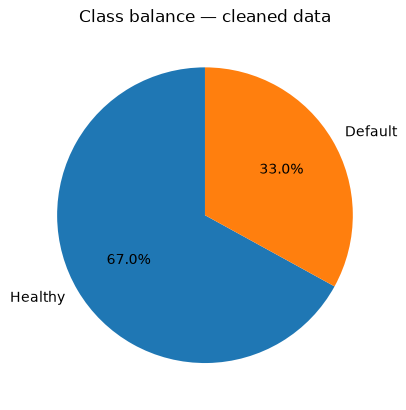

In [28]:
plot_class_balance(df, "Class balance — cleaned data", save_as="class_balance.png")

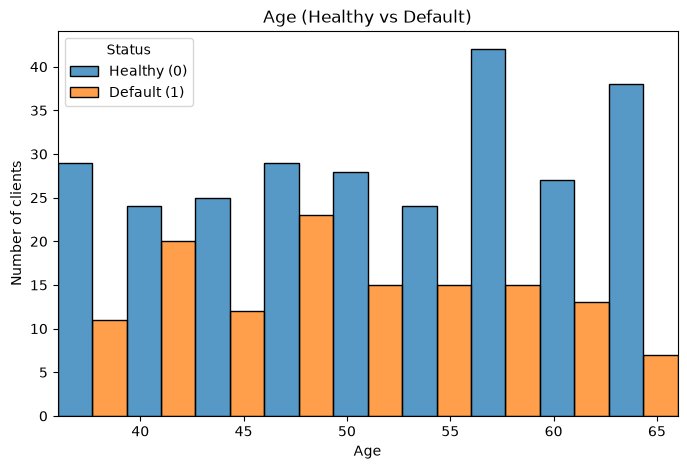

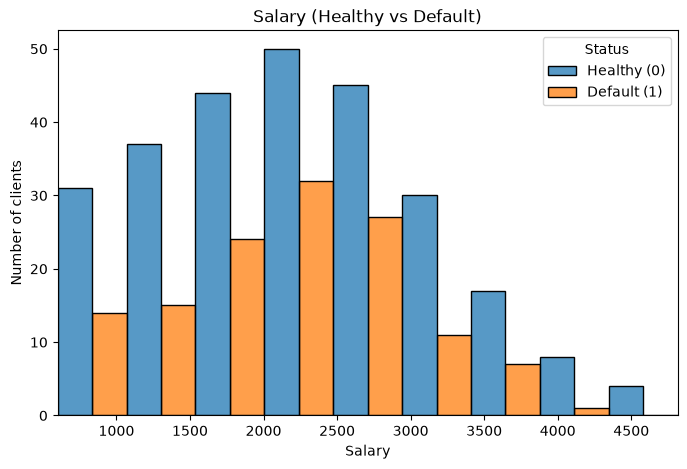

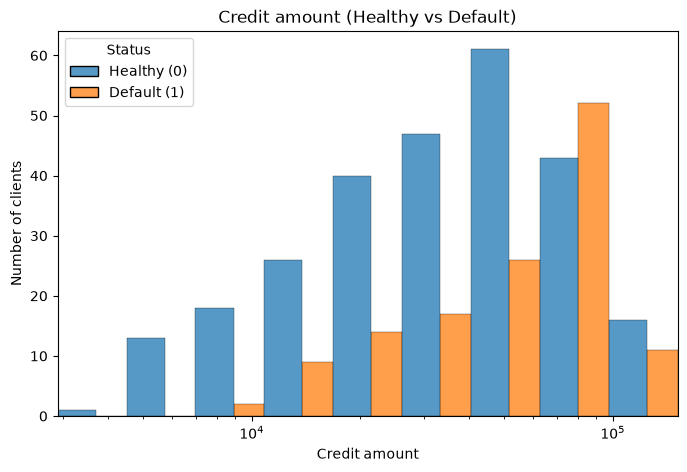

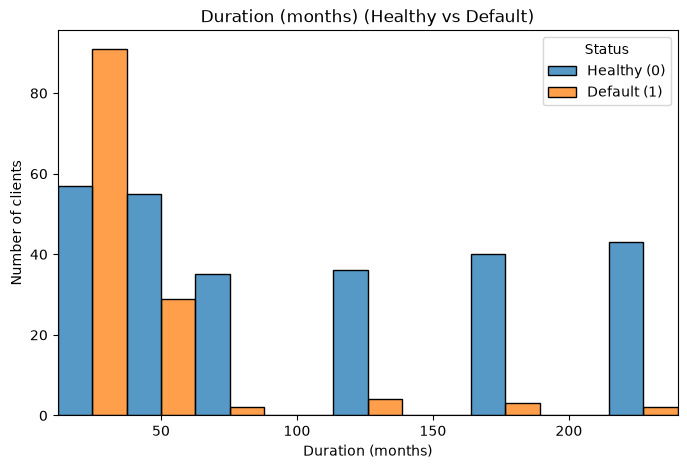

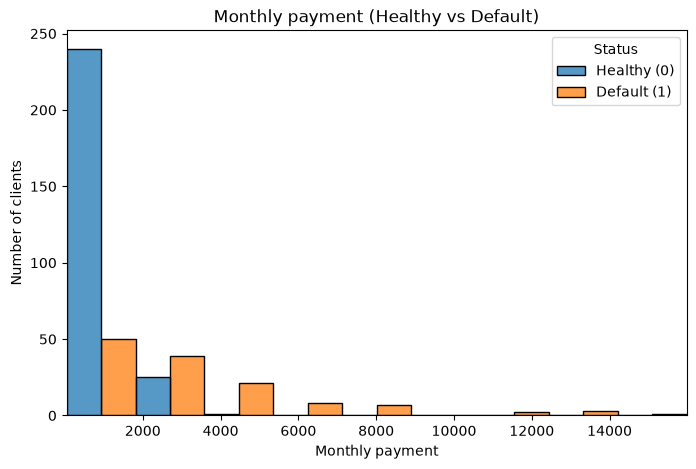

In [29]:
HIST_LABELS = {
    "age": "Age",
    "salary": "Salary",
    "credit_amount": "Credit amount",
    "duration": "Duration (months)",
    "monthly_payment": "Monthly payment",
}


def plot_distribution(var):
    """Histogram of one variable, split by default status."""
    xmin, xmax = df[var].min(), df[var].max()
    log_scale = var == "credit_amount"
    bins = np.logspace(np.log10(xmin), np.log10(xmax), 10) if log_scale else np.linspace(xmin, xmax, 10)

    plt.figure(figsize=(8, 5))
    ax = sns.histplot(data=df, x=var, hue="default", bins=bins, multiple="dodge", edgecolor="black")
    if log_scale:
        ax.set_xscale("log")
    ax.set_xlim(xmin, xmax)
    ax.set_title(f"{HIST_LABELS[var]} (Healthy vs Default)")
    ax.set_xlabel(HIST_LABELS[var])
    ax.set_ylabel("Number of clients")

    legend = ax.get_legend()
    if legend is not None:
        legend.set_title("Status")
        for text in legend.get_texts():
            text.set_text({"0": "Healthy (0)", "1": "Default (1)"}.get(text.get_text(), text.get_text()))
    plt.show()


for var in HIST_LABELS:
    plot_distribution(var)

## 5. Feature engineering and train/test split

### 5.1 Financial ratios
- `debt_to_income` — monthly payment relative to monthly salary
- `credit_to_annual_income` — loan size relative to yearly salary
- `total_repayment` — total amount repaid over the loan life

In [30]:
df["debt_to_income"] = df["monthly_payment"] / df["salary"]
df["credit_to_annual_income"] = df["credit_amount"] / (df["salary"] * 12)
df["total_repayment"] = df["monthly_payment"] * df["duration"]

NUM_COLS = [
    "age", "salary", "credit_amount", "duration", "monthly_payment",
    "debt_to_income", "credit_to_annual_income", "total_repayment",
]
CAT_COLS = ["profession"]
df[NUM_COLS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,397.0,51.15,8.45,36.00,44.00,51.00,59.00,66.00
salary,397.0,2196.11,882.73,600.00,1552.00,2206.00,2748.00,4815.00
credit_amount,397.0,47963.62,30749.41,2897.99,21847.11,42939.47,68107.27,151158.24
duration,397.0,87.32,73.74,12.00,36.00,60.00,120.00,240.00
monthly_payment,397.0,1608.07,2136.46,41.47,395.69,835.90,1977.46,15980.43
debt_to_income,397.0,0.76,0.91,0.02,0.19,0.42,0.90,5.05
credit_to_annual_income,397.0,1.82,0.89,0.25,1.03,1.80,2.59,3.33
total_repayment,397.0,63111.13,40985.91,3483.48,28200.60,56181.72,88250.40,198165.60


### 5.2 Train/test split
The split is done **before** any step that learns from the data (rare-profession grouping, scaling, SMOTE) to avoid leakage.
It is stratified so that train and test keep the same default rate.

In [31]:
X = df[NUM_COLS + CAT_COLS]
y = df["default"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

# Group rare professions into "other" — the list is learned on the TRAIN set only
top_professions = X_train["profession"].value_counts().nlargest(TOP_N_PROFESSIONS).index
X_train = X_train.assign(profession=X_train["profession"].where(X_train["profession"].isin(top_professions), "other"))
X_test = X_test.assign(profession=X_test["profession"].where(X_test["profession"].isin(top_professions), "other"))

print(f"Train: {len(X_train)}/{len(y)} rows — default rate {y_train.mean():.1%}")
print(f"Test : {len(X_test)}/{len(y)} rows — default rate {y_test.mean():.1%}")


Train: 317/397 rows — default rate 33.1%
Test : 80/397 rows — default rate 32.5%


## 6. Modeling: logistic regression

Logistic regression is chosen for its **interpretability** (coefficients and odds ratios), which matters in credit scoring.

The pipeline chains scaling/encoding → SMOTE → classifier.
Because SMOTE sits inside the pipeline, synthetic samples are generated **only on the training part of each cross-validation fold** — never on validation data.
Regularization is kept strong (`C=0.5`) because the dataset is small.

In [32]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), NUM_COLS),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), CAT_COLS),
    ],
    sparse_threshold=0,  # always return a dense array (needed by SMOTE and SHAP)
)

model = ImbPipeline(steps=[
    ("preprocessing", preprocessor),
    ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=3)),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        C=0.5,
        max_iter=1000,
        random_state=RANDOM_STATE,
    )),
])

In [33]:
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

roc_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")
f1_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1")

print(f"=== Cross-validation ({N_FOLDS}-fold, training set) ===")
print(f"ROC-AUC : {roc_scores.mean():.3f} ± {roc_scores.std():.3f}")
print(f"F1-score: {f1_scores.mean():.3f} ± {f1_scores.std():.3f}")

=== Cross-validation (3-fold, training set) ===
ROC-AUC : 0.898 ± 0.017
F1-score: 0.734 ± 0.019


In [34]:
model.fit(X_train, y_train)
y_proba = model.predict_proba(X_test)[:, 1]

## 7. Performance evaluation

### 7.1 Choosing the decision threshold
The default threshold of 0.5 is rarely optimal for imbalanced data.
The optimal threshold (Youden's J = TPR − FPR) is selected on **cross-validated predictions of the training set**, so the test set stays untouched for the final evaluation.

In [35]:
proba_cv = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
fpr_cv, tpr_cv, thresholds_cv = roc_curve(y_train, proba_cv)
best_threshold = thresholds_cv[np.argmax(tpr_cv - fpr_cv)]
print(f"Optimal threshold (Youden, train CV): {best_threshold:.2f}")

y_pred_default = (y_proba >= 0.5).astype(int)
y_pred_optimal = (y_proba >= best_threshold).astype(int)

Optimal threshold (Youden, train CV): 0.54


### 7.2 Classification report (test set)

In [36]:
print("=== Threshold = 0.50 ===")
print(classification_report(y_test, y_pred_default, target_names=["Healthy", "Default"], zero_division=0))
print(f"=== Threshold = {best_threshold:.2f} (optimal) ===")
print(classification_report(y_test, y_pred_optimal, target_names=["Healthy", "Default"], zero_division=0))

=== Threshold = 0.50 ===
              precision    recall  f1-score   support

     Healthy       0.86      0.89      0.87        54
     Default       0.75      0.69      0.72        26

    accuracy                           0.82        80
   macro avg       0.80      0.79      0.80        80
weighted avg       0.82      0.82      0.82        80

=== Threshold = 0.54 (optimal) ===
              precision    recall  f1-score   support

     Healthy       0.84      0.89      0.86        54
     Default       0.74      0.65      0.69        26

    accuracy                           0.81        80
   macro avg       0.79      0.77      0.78        80
weighted avg       0.81      0.81      0.81        80



### 7.3 Confusion matrices

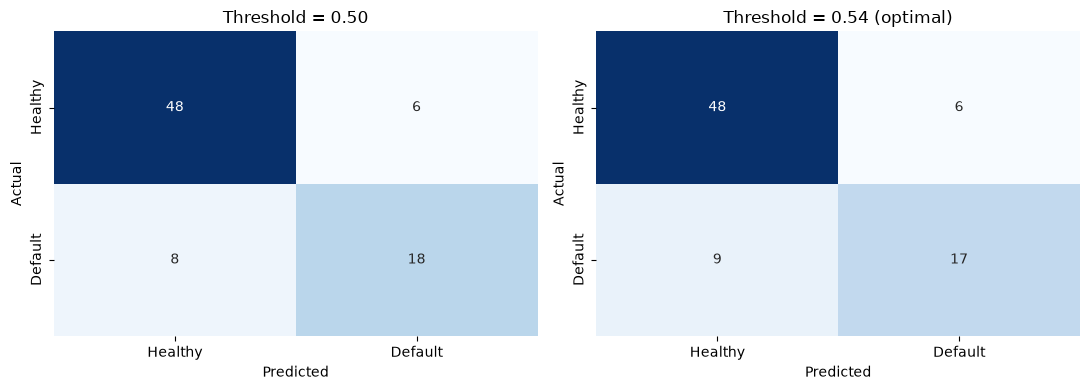

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, preds, title in zip(
    axes,
    [y_pred_default, y_pred_optimal],
    ["Threshold = 0.50", f"Threshold = {best_threshold:.2f} (optimal)"],
):
    sns.heatmap(
        confusion_matrix(y_test, preds), annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["Healthy", "Default"], yticklabels=["Healthy", "Default"], ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

### 7.4 ROC curve

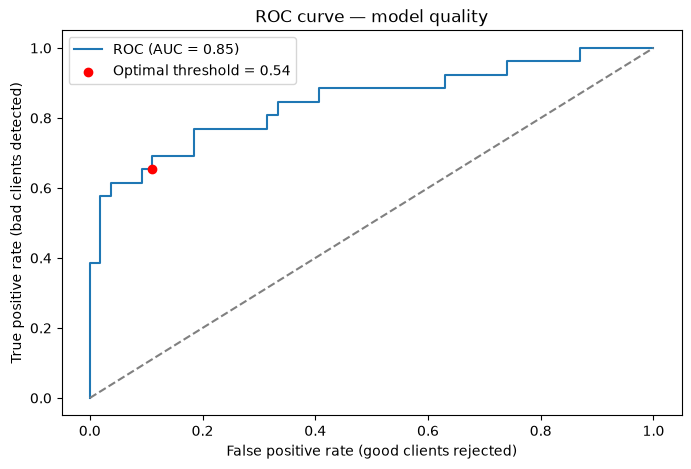

In [40]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

# Position of the chosen threshold on the test ROC curve
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_optimal).ravel()

plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label=f"ROC (AUC = {auc:.2f})")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.scatter(fp / (fp + tn), tp / (tp + fn), color="red", zorder=3,
            label=f"Optimal threshold = {best_threshold:.2f}")
plt.xlabel("False positive rate (good clients rejected)")
plt.ylabel("True positive rate (bad clients detected)")
plt.title("ROC curve — model quality")
plt.legend()
plt.show()

### 7.5 Results summary

In [41]:
results = pd.DataFrame(
    {
        "ROC-AUC": [auc, auc],
        "Precision": [precision_score(y_test, p, zero_division=0) for p in (y_pred_default, y_pred_optimal)],
        "Recall": [recall_score(y_test, p, zero_division=0) for p in (y_pred_default, y_pred_optimal)],
        "F1": [f1_score(y_test, p, zero_division=0) for p in (y_pred_default, y_pred_optimal)],
    },
    index=["Threshold 0.50", f"Threshold {best_threshold:.2f}"],
).round(3)
results

,ROC-AUC,Precision,Recall,F1
Threshold 0.50,0.846,0.750,0.692,0.720
Threshold 0.54,0.846,0.739,0.654,0.694


## 8. Model interpretation

### 8.1 Coefficients and odds ratios
Inputs are standardized, so numeric coefficients are comparable with each other.
A positive coefficient (odds ratio > 1) raises the predicted risk of default.

In [42]:
cat_features = (
    model.named_steps["preprocessing"]
    .named_transformers_["cat"]
    .get_feature_names_out(CAT_COLS)
    .tolist()
)
all_features = NUM_COLS + cat_features

coefficients = model.named_steps["classifier"].coef_[0]
coef_df = pd.DataFrame({
    "Variable": all_features,
    "Coefficient": coefficients,
    "Odds Ratio": np.exp(coefficients),
}).sort_values("Coefficient", ascending=False)
coef_df.round(3)

,Variable,Coefficient,Odds Ratio
5,debt_to_income,1.673,5.330
4,monthly_payment,0.507,1.660
7,total_repayment,0.421,1.524
13,profession_other,0.368,1.445
15,profession_self-employed,0.232,1.261
6,credit_to_annual_income,0.176,1.192
16,profession_teacher,0.171,1.186
10,profession_farmer,0.142,1.152
9,profession_engineer,0.037,1.038
2,credit_amount,-0.060,0.942


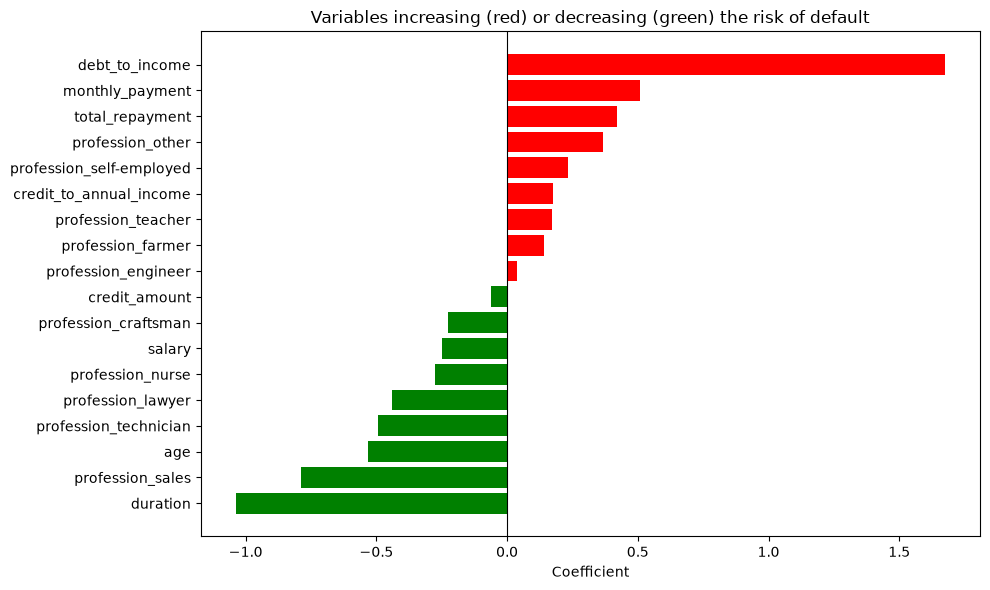

In [44]:
coef_sorted = coef_df.sort_values("Coefficient")
colors = ["red" if c > 0 else "green" for c in coef_sorted["Coefficient"]]

plt.figure(figsize=(10, 6))
plt.barh(coef_sorted["Variable"], coef_sorted["Coefficient"], color=colors)
plt.axvline(x=0, color="black", linewidth=0.8)
plt.title("Variables increasing (red) or decreasing (green) the risk of default")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()

### 8.2 SHAP values
Global view (which variables matter most) and local view (why one specific client is scored as risky).
Static plots are used so that they render correctly on GitHub.

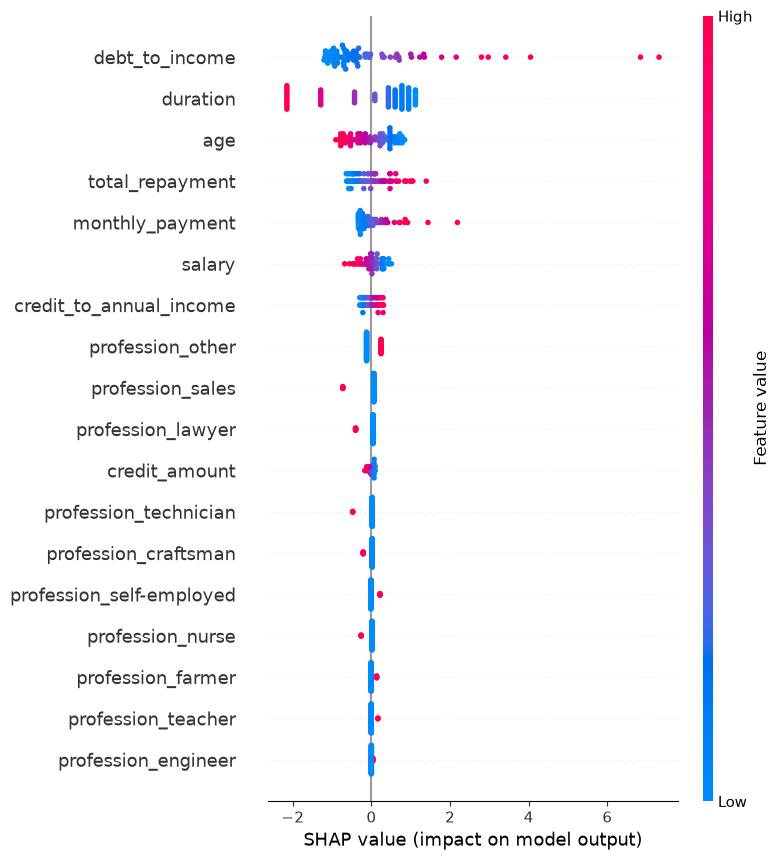

In [46]:
preprocessor_fitted = model.named_steps["preprocessing"]
classifier = model.named_steps["classifier"]

X_test_transformed = preprocessor_fitted.transform(X_test)
explainer = shap.LinearExplainer(classifier, X_test_transformed)
shap_values = explainer.shap_values(X_test_transformed)

# Global importance
shap.summary_plot(shap_values, X_test_transformed, feature_names=all_features, show=False)
plt.show()

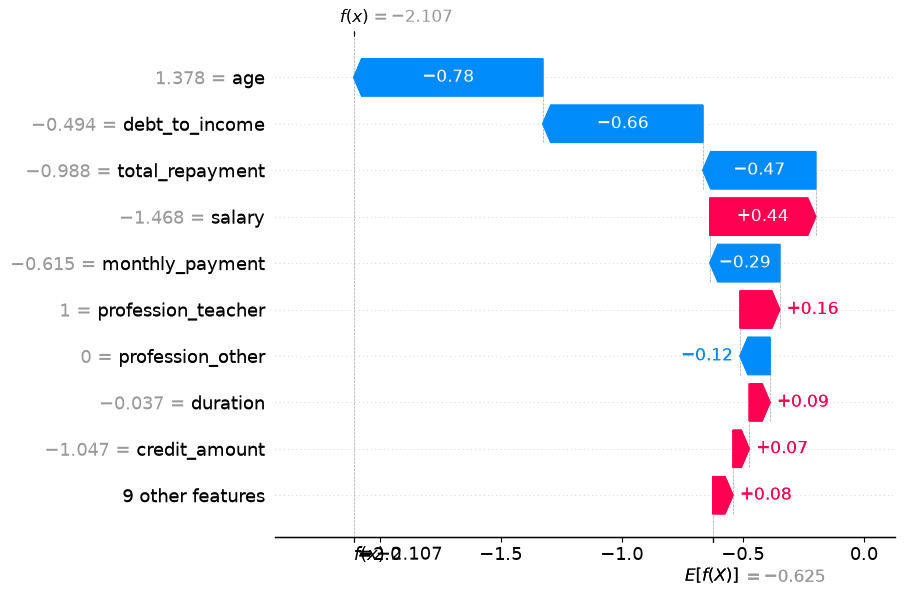

In [48]:
# Local explanation for one client (first row of the test set)
explanation = shap.Explanation(
    values=shap_values[0],
    base_values=explainer.expected_value,
    data=X_test_transformed[0],
    feature_names=all_features,
)
shap.plots.waterfall(explanation, show=False)
plt.show()

## 9. Conclusions and limitations

**Conclusions**

> ✏️ *To complete after running the notebook on the real data:* state the test ROC-AUC and recall from section 7.5,
> then 2–3 sentences on the variables that raise or lower default risk (section 8) and what it means for a credit officer.

**Limitations**
- **Small dataset** — metrics have high variance; the 3-fold cross-validation standard deviation shows how unstable they are.
- **SMOTE + `class_weight="balanced"`** both rebalance the classes. It would be worth testing each separately.
- **Synthetic samples** — SMOTE creates artificial minority examples, which can make the model overconfident.
- **No external validation** — results come from a single bank's data and a single train/test split.
- **Age** is computed relative to the run date, so it drifts slightly over time.

**Possible next steps**
- Compare with gradient boosting (XGBoost / LightGBM) and a simple decision tree.
- Calibrate probabilities and build a score card (points per variable).
- Choose the threshold from business costs (cost of a missed default vs. a refused good client).